# Deep Learning HW 3 Part 1
Author: Daniel Bond

In [ ]:
import ast
import random
import re
import string
from collections import Counter
from pathlib import Path
from typing import List

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

seed = 67
random.seed(seed)
np.random.seed(seed)

DATA_DIR = Path("data")
IMG_DIR = Path("images")
IMG_DIR.mkdir(exist_ok=True)
RU_ROWS = 500_000

uk_df = pd.read_csv(DATA_DIR / "uk_geo_dataset.csv")
ru_df = pd.read_csv(DATA_DIR / "ru_geo_dataset.csv", nrows=RU_ROWS)
sample_df = pd.read_csv(DATA_DIR / "labeling_sample.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

for df in (uk_df, ru_df, sample_df):
    df["loc_markers"] = df["loc_markers"].apply(ast.literal_eval)
sample_df["locations"] = sample_df["locations"].apply(ast.literal_eval)

datasets = {"uk_geo": uk_df, "ru_geo": ru_df, "labeling_sample": sample_df, "test": test_df}
for name, df in datasets.items():
    print(f"{name}: {df.shape}")

uk_geo: (1010000, 5)
ru_geo: (500000, 6)
labeling_sample: (26, 3)
test: (477, 3)


## EDA

In [2]:
spans_match = all(
    [text[a:b] for a, b in markers] == locations
    for text, markers, locations in zip(sample_df["text"], sample_df["loc_markers"], sample_df["locations"])
)
print(f"labeling_sample: locations == text[l:r] in every text: {spans_match}")
print(f"test: all locations empty: {(test_df['locations'] == '[]').all()}")
print(f"uk_geo is_valid: {uk_df['is_valid'].value_counts().to_dict()}")
print(f"ru_geo: {ru_df['doc_id'].nunique()} documents in the first {RU_ROWS} rows")
print(f"duplicated texts in test: {test_df['text'].duplicated().sum()}")
print(f"labeling_sample texts also in test: {sample_df['text'].isin(test_df['text']).sum()}")

labeling_sample: locations == text[l:r] in every text: True
test: all locations empty: True
uk_geo is_valid: {0: 1000000, 1: 10000}
ru_geo: 43556 documents in the first 500000 rows
duplicated texts in test: 0
labeling_sample texts also in test: 0


In [3]:
UA_CHARS, RU_CHARS = set("іїєґ"), set("ыэъё")
EMOJI = r"[\U0001F300-\U0001FAFF\u2600-\u27BF]"


def language(text):
    chars = set(text.lower())
    ua, ru = bool(chars & UA_CHARS), bool(chars & RU_CHARS)
    return "mixed" if ua and ru else "ua" if ua else "ru" if ru else "unknown"


rows = {}
for name, df in datasets.items():
    n_locs = df["loc_markers"].str.len() if "loc_markers" in df else pd.Series(np.nan, index=df.index)
    rows[name] = {
        "texts": len(df),
        "median chars": df["text"].str.len().median(),
        "max chars": df["text"].str.len().max(),
        "multiline %": df["text"].str.contains("\n").mean() * 100,
        "emoji %": df["text"].str.contains(EMOJI).mean() * 100,
        "has location %": (n_locs > 0).mean() * 100 if n_locs.notna().any() else np.nan,
        "locations / text": n_locs.mean(),
        "locations / 100 chars": n_locs.sum() / df["text"].str.len().sum() * 100 if n_locs.notna().any() else np.nan,
    }
display(pd.DataFrame(rows).T.round(2))

lang = pd.concat(
    {name: df["text"].apply(language).value_counts(normalize=True) for name, df in datasets.items()}, axis=1
)
display(lang.fillna(0).mul(100).round(1))

,texts,median chars,max chars,multiline %,emoji %,has location %,locations / text,locations / 100 chars
uk_geo,1010000.0,91.0,255.0,0.00,0.01,23.11,0.34,0.33
ru_geo,500000.0,100.0,786.0,0.00,0.05,27.77,0.43,0.39
labeling_sample,26.0,217.5,1118.0,80.77,69.23,61.54,1.23,0.42
test,477.0,264.0,3682.0,85.12,60.17,NaN,NaN,NaN


,uk_geo,ru_geo,labeling_sample,test
text,,,,
ua,98.7,0.0,92.3,89.5
unknown,1.3,21.4,3.8,3.4
mixed,0.1,0.0,0.0,0.2
ru,0.0,78.5,3.8,6.9


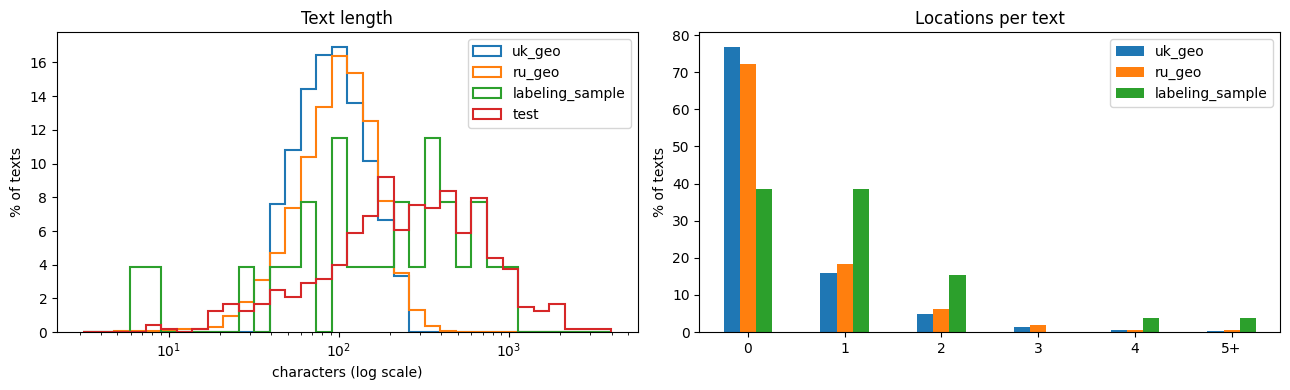

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.logspace(0.5, 3.6, 35)
for name, df in datasets.items():
    lengths = df["text"].str.len()
    axes[0].hist(lengths, bins=bins, weights=np.full(len(lengths), 100 / len(lengths)),
                 histtype="step", lw=1.5, label=name)
axes[0].set_xscale("log")
axes[0].set_title("Text length")
axes[0].set_xlabel("characters (log scale)")
axes[0].set_ylabel("% of texts")
axes[0].legend()

per_text = pd.DataFrame({
    name: datasets[name]["loc_markers"].str.len().clip(upper=5).value_counts(normalize=True)
    for name in ["uk_geo", "ru_geo", "labeling_sample"]
}).reindex(range(6), fill_value=0).fillna(0) * 100
per_text.index = ["0", "1", "2", "3", "4", "5+"]
per_text.plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Locations per text")
axes[1].set_ylabel("% of texts")
plt.tight_layout()
plt.savefig(IMG_DIR / "eda_lengths_locations.png", dpi=120, bbox_inches="tight")
plt.show()

There are four datasets:
- `uk_geo` - 1M Ukrainian news sentences
- `ru_geo` - 8M Russian news sentences. 

LOC, ORG and PER spans were produced by existing NER models.

- `labeling_sample` - 26 texts. Every `locations` entry is exactly `text[l:r]` of its marker, so the task is span extraction: predicted strings should be cut from the original text.
- `test` - 477 texts, about 224 of them in the public LB.

Test texts are Telegram posts, not news sentences: median 264 vs 91 characters (up to 3682), 85% have line breaks and 60% have emoji, and the training has almost none.

Test is 90% Ukrainian and 7% Russian, so `uk_geo` is the main training source and `ru_geo` is extra data - a subsample of its 8 mil rows is enough.

### What is a location

In [5]:
ADDRESS = re.compile(
    r"\b(?:вул|улиц|просп|бульв|пров|переул|площ|пл\.|майдан|набережн|шосе|узвіз|ТЦ|ТРЦ|ЖК|район|р-н|масив|метро|станц)",
    re.IGNORECASE,
)


def location_strings(df):
    return pd.Series([text[a:b] for text, markers in zip(df["text"], df["loc_markers"]) for a, b in markers])


locs = {name: location_strings(datasets[name]) for name in ["uk_geo", "ru_geo", "labeling_sample"]}
display(pd.DataFrame({
    name: {
        "locations": len(s),
        "unique": s.nunique(),
        "multi-word %": s.str.contains(r"\s").mean() * 100,
        "street/district/landmark %": s.str.contains(ADDRESS).mean() * 100,
        "starts lowercase %": s.str.match(r"[a-zа-яіїєґё]").mean() * 100,
        "has digit %": s.str.contains(r"\d").mean() * 100,
    }
    for name, s in locs.items()
}).T.round(2))

for name in ["uk_geo", "ru_geo"]:
    print(f"{name} top-10:", locs[name].value_counts().head(10).to_dict())
print("labeling_sample, all:", locs["labeling_sample"].tolist())

,locations,unique,multi-word %,street/district/landmark %,starts lowercase %,has digit %
uk_geo,345114.0,45430.0,15.40,3.52,2.13,0.73
ru_geo,213129.0,17157.0,12.27,1.21,0.07,0.03
labeling_sample,32.0,30.0,28.12,21.88,12.50,6.25


uk_geo top-10: {'України': 24432, 'Україні': 16849, 'США': 8862, 'Росії': 7704, 'Україна': 7425, 'Києві': 6541, 'Києва': 4061, 'Україну': 4036, 'Криму': 3510, 'РФ': 3349}
ru_geo top-10: {'России': 23462, 'США': 13839, 'Украины': 6276, 'Россия': 3332, 'Москве': 3057, 'Москвы': 2645, 'Сирии': 2600, 'Великобритании': 2219, 'РФ': 2134, 'Россию': 2082}
labeling_sample, all: ['Проспект Бандери', 'Київщині', 'Чорнобиль', 'Київ', 'Тетерів', 'Фастів', 'Біла Церква', 'Миронівка', 'Бориспіль', 'Яготин', 'Баришівка', 'проспекті Івасюка', 'Києва', 'Хелма', 'Києву', 'ТЦ Аркадія', 'Фастовском', 'Бучанском', 'Троєщині', 'Шевченківському районі', 'Героїв Дніпра', "вул. Солом'янська, 28", 'Києвом', 'Васильковом', 'Києва', 'Броварах', 'Київщині', 'Києві', 'Подолі', 'Пскові', 'вулиці Здолбунівській', 'вул. Здолбунівська, 1']


In [6]:
news_locations = set(locs["uk_geo"]) | set(locs["ru_geo"])
seen = locs["labeling_sample"].isin(news_locations)
print(f"labeling_sample locations that appear as a location in uk/ru news: {seen.mean():.0%}")
print("never seen:", locs["labeling_sample"][~seen].tolist())

kyiv = locs["uk_geo"][locs["uk_geo"].str.match(r"(Київ|Києв)")]
print("\nSurface forms of Kyiv in uk_geo:", kyiv.value_counts().head(8).to_dict())

labeling_sample locations that appear as a location in uk/ru news: 75%
never seen: ['Проспект Бандери', 'проспекті Івасюка', 'ТЦ Аркадія', 'Фастовском', 'Бучанском', "вул. Солом'янська, 28", 'вулиці Здолбунівській', 'вул. Здолбунівська, 1']

Surface forms of Kyiv in uk_geo: {'Києві': 6541, 'Києва': 4061, 'Київ': 2629, 'Києвом': 548, 'Київщині': 344, 'Київській області': 313, 'Київської області': 301, 'Києву': 191}


- News locations are mostly countries and big cities, only 3.5% are streets, districts or landmarks, in the sample it is 22%.
- 25% of the sample locations never appear as a location in 1.5M news sentences. A table built from the training data cannot find them; the model has to use context.
- Locations come in changed forms: Kyiv has 8+ forms in `uk_geo`. The metric compares strings, so the prediction must keep the form from the text.

I expect the biggest gap between validation on news and the LB to come from addresses.

### Silver label artifacts

In [7]:
def touching_runs(text, markers):
    """Location spans with no gap between them, e.g. 'Івано' + '-' + 'Франківську'."""
    runs = []
    for a, b in sorted(markers):
        if runs and runs[-1][1] == a:
            runs[-1] = (runs[-1][0], b, runs[-1][2] + 1)
        else:
            runs.append((a, b, 1))
    return [text[a:b] for a, b, n in runs if n > 1]


for name in ["uk_geo", "ru_geo", "labeling_sample"]:
    df = datasets[name]
    runs = pd.Series([r for text, markers in zip(df["text"], df["loc_markers"]) for r in touching_runs(text, markers)])
    print(f"{name}: {len(runs)} split entities ({len(runs) / len(locs[name]) * 100:.2f}% of location spans)")
    if len(runs):
        print("   ", runs.value_counts().head(8).to_dict())

uk_geo: 2628 split entities (0.76% of location spans)
    {'Івано-Франківську': 564, 'Івано-Франківська': 428, 'Івано-Франківській області': 373, 'Нью-Йорку': 219, 'Івано-Франківської області': 200, 'Івано-Франківськ': 58, 'Нью-Йорка': 49, 'Києво-Печерської лаври': 38}
ru_geo: 31 split entities (0.01% of location spans)
    {'Одиша (Орисса)': 2, 'Северном Сентинельском острове (Индия': 1, 'Новомосковского округов (ТиНАО': 1, 'Малокурильского (Шикотан)': 1, 'Новомосковском округах (ТиНАО': 1, 'Новомосковского округов (ТиНАО)': 1, 'ЛНР (Луганской народной республике': 1, 'Невада (NAC)': 1}
labeling_sample: 0 split entities (0.00% of location spans)


Labels in `uk_geo` split dash names into separate spans: `Івано-Франківську` is tagged as `Івано`, `-`, `Франківську` (2628 cases, 0.8% of the spans - Івано-Франківськ, Нью-Йорк, Києво-Печерська лавра). `ru_geo` has almost none (bracket artifacts only), and the labeling sample has none.

### Vocabulary

In [8]:
WORD = re.compile(r"\w+(?:[-'ʼ’]\w+)*")

train_vocab = Counter()
for text in uk_df.loc[uk_df["is_valid"] == 0, "text"]:
    train_vocab.update(WORD.findall(text))
train_vocab_lower = {w.lower() for w in train_vocab}


def oov(words):
    words = list(words)
    return {
        "words": len(words),
        "OOV %": np.mean([w not in train_vocab for w in words]) * 100,
        "OOV lowercased %": np.mean([w.lower() not in train_vocab_lower for w in words]) * 100,
    }


def words_of(texts):
    return (w for text in texts for w in WORD.findall(text))


print(f"uk_geo train vocabulary: {len(train_vocab)} words, {sum(c >= 5 for c in train_vocab.values())} with 5+ occurrences")
display(pd.DataFrame({
    "uk_geo valid": oov(words_of(uk_df.loc[uk_df["is_valid"] == 1, "text"])),
    "test": oov(words_of(test_df["text"])),
    "labeling_sample locations": oov(words_of(locs["labeling_sample"])),
}).T.round(2))

uk_geo train vocabulary: 522250 words, 135939 with 5+ occurrences


,words,OOV %,OOV lowercased %
uk_geo valid,145038.0,1.81,1.58
test,25674.0,6.76,5.56
labeling_sample locations,43.0,6.98,6.98


A word vocabulary from 1M `uk_geo` sentences has 522k words. The out-of-vocabulary rate is 1.8% on `uk_geo` valid but 6.8% on test. 7% of the words in the sample locations are unknown.

## Metric analysis

The metric is micro F1

In [9]:
def hard_processing(text):
    text = re.sub(r"[{re.escape(string.punctuation)}]", "", text)
    text = re.sub(r'\d', '', text)
    text = re.sub(r'\b\w\b\s?', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()


def comp_metric(y_true: List[List[str]], y_pred: List[List[str]]):
    assert len(y_true) == len(y_pred)
    tp, fp, fn, p,  = 0.0, 0.0, 0.0, 0.0

    for y_true_sample, y_pred_sample in zip(y_true, y_pred):
        y_true_sample = set([hard_processing(s) for s in y_true_sample])
        y_pred_sample = set([hard_processing(s) for s in y_pred_sample])

        tp += len(y_true_sample & y_pred_sample)
        fp += len(y_pred_sample - y_true_sample)
        fn += len(y_true_sample - y_pred_sample)
        p += len(y_true_sample)

    if tp + fp == 0:
        if p == 0:
            precision = 1.0
        else:
            precision = 0.0
    else:
        precision = tp/(tp + fp)

    if tp + fn == 0:
        if p == 0:
            recall = 1.0
        else:
            recall = 0.0
    else:
        recall = tp/(tp + fn)

    if precision + recall == 0:
        f1 = 0
    else:
        f1 = 2 * precision * recall / (precision + recall)
    return round(f1, 8)

In [10]:
examples = ["Київ", "КИЇВ", "м. Київ", "Києві", "с. Гатне", "вул. Шевченка 12", "вул. Шевченка",
            "Слов'янськ", "Словʼянськ", "28"]
pd.DataFrame({"normalized": [hard_processing(s) for s in examples]}, index=examples)

,normalized
Київ,київ
КИЇВ,київ
м. Київ,київ
Києві,києві
с. Гатне,гатне
вул. Шевченка 12,вул шевченка
вул. Шевченка,вул шевченка
Слов'янськ,слов'янськ
Словʼянськ,словʼянськ
28,


- Case, digits and one-letter words are dropped
- Different word versions are not normalized
- Different apostrophes give different strings

In [11]:
gold = sample_df["locations"].tolist()
NOMINATIVE = {"Києва": "Київ", "Києву": "Київ", "Києвом": "Київ", "Києві": "Київ", "Київщині": "Київщина",
              "Броварах": "Бровари", "Троєщині": "Троєщина", "Васильковом": "Васильків", "Хелма": "Хелм"}
biggest = int(np.argmax([len(g) for g in gold]))

scenarios = {
    "perfect": gold,
    "empty": [[] for _ in gold],
    "every location twice": [g + g for g in gold],
    "nominative forms": [[NOMINATIVE.get(l, l) for l in g] for g in gold],
    "street type dropped": [[l.split(" ", 1)[1] if ADDRESS.match(l) and " " in l else l for l in g] for g in gold],
    "extra number '28'": [g + ["28"] for g in gold],
    "only the longest text": [g if i == biggest else [] for i, g in enumerate(gold)],
}
pd.Series({name: comp_metric(gold, pred) for name, pred in scenarios.items()}, name="F1").to_frame()

,F1
perfect,1.000000
empty,0.000000
every location twice,1.000000
nominative forms,0.656250
street type dropped,0.812500
extra number '28',0.711111
only the longest text,0.476190


In [12]:
rng = np.random.default_rng(seed)


def simulated_model(texts, gold, keep=0.6, fp_rate=0.4):
    """Finds each location with p=keep, adds a random capitalized word as a false positive with p=fp_rate."""
    preds = []
    for text, g in zip(texts, gold):
        pred = [l for l in g if rng.random() < keep]
        capitalized = re.findall(r"\b[А-ЯІЇЄҐ]\w+", text)
        if capitalized and rng.random() < fp_rate:
            pred.append(rng.choice(capitalized))
        preds.append(pred)
    return preds


pred = simulated_model(sample_df["text"], gold)
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(gold), len(gold))
    boot.append(comp_metric([gold[i] for i in idx], [pred[i] for i in idx]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"simulated model on labeling_sample: F1 = {comp_metric(gold, pred):.3f}, bootstrap 95% CI [{lo:.3f}, {hi:.3f}]")
print(f"the longest text holds {len(gold[biggest])} of {sum(map(len, gold))} gold locations")

simulated model on labeling_sample: F1 = 0.735, bootstrap 95% CI [0.549, 0.839]
the longest text holds 10 of 32 gold locations


- Duplicates don't matter
- Predicting nothing gives 0
- The nominative form costs 34 points, dropping the street type costs 19 points
- Every junk prediction is a false positive
- Long posts with lists of places dominate the score

#### Strengths
- Measures the list of places in a text, regardless of position and number of mentions
- Lenient to formatting and duplicates
- Ignores true negatives

#### Weaknesses
- No partial credit for texts with extra/missing words
- Different forms of one word are different strings
- Long posts dominate

#### Edge cases
- Predictions that normalize to an empty string are a guaranteed FP, should be filtered out
- Different apostrophes give different strings, must be copied from the text

#### Complementary metrics
1. Precision and recall - threshold tuning trades one for the other
2. Competition F1 by group: language, location type, text length.

#### Alternative
Entity-level span F1: a prediction is correct only if its character span and type match a gold span exactly. It scores positions instead of strings, so different forms stop mattering, and it counts every mention. It is the standard NER metric and the markers already exist.